<a href="https://colab.research.google.com/github/aleakucing/PCVK26_14_IBRA/blob/main/Week7_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

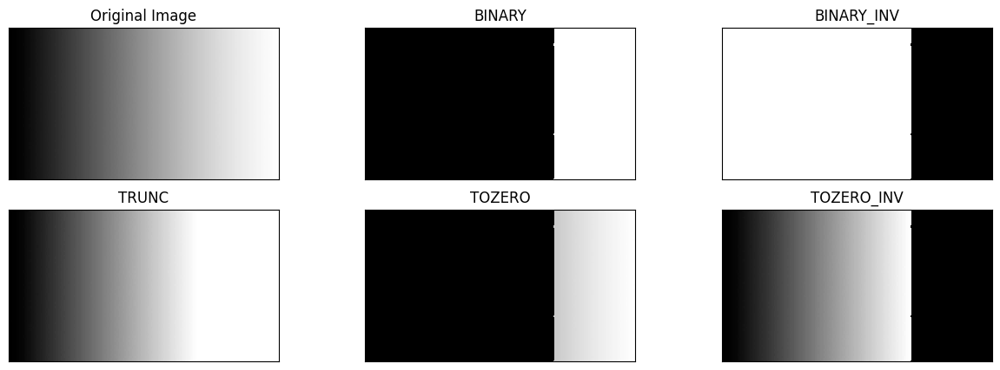

In [ ]:
#3. global threshold dengan threshold= 200
filename = '/content/drive/MyDrive/PCVK_2026/Minggu 7/gradient.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

thresh = 200
maxval = 255

thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)

thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)

thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)

thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)

thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC','TOZERO','TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

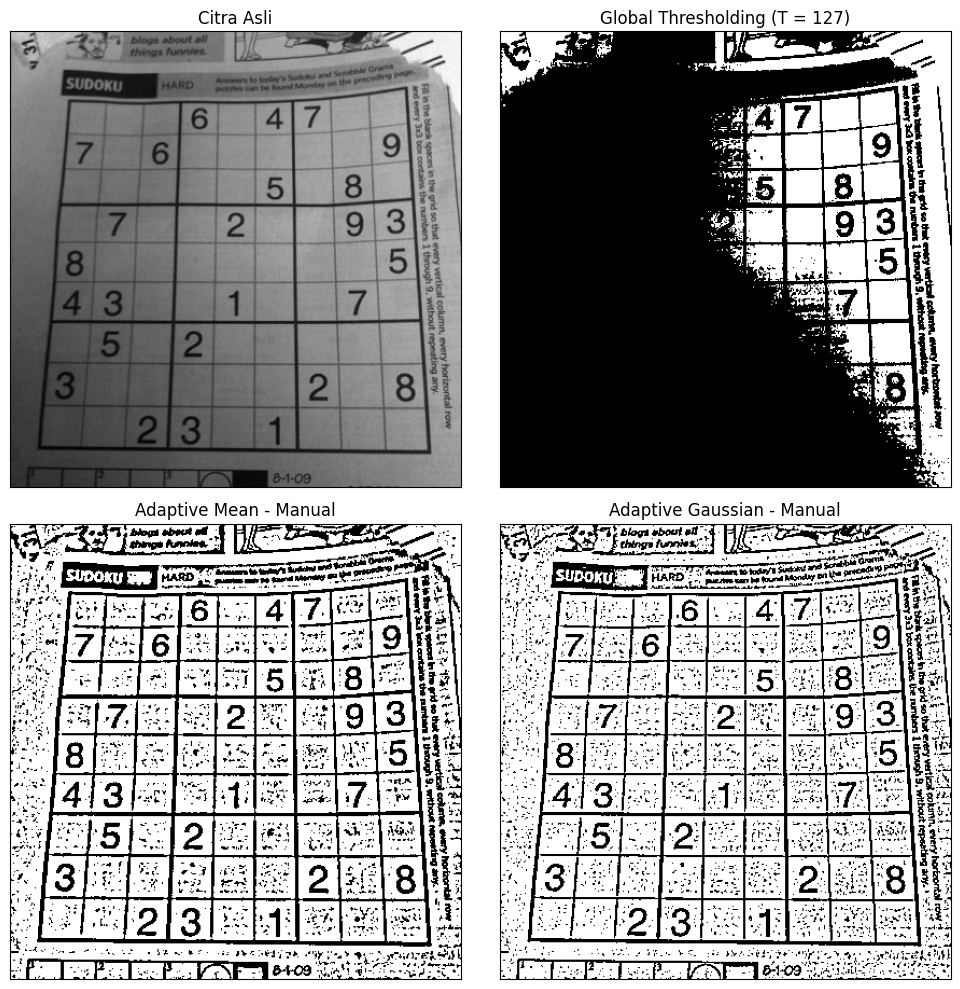

In [ ]:
# 4.Adaptive threshold tanpa cv.threshold, cv.adaptiveThreshold, atau fungsi filter siap pakai

filename = '/content/drive/MyDrive/PCVK_2026/Minggu 7/sudoku-original.jpg'
img = cv.imread(filename, 0)

global_thresh = np.where(img > 127, 255, 0).astype(np.uint8)

block_size = 11
pad = block_size // 2
C = 2
sigma = 2

h, w = img.shape
padded_img = np.pad(img, pad, mode='reflect').astype(np.float64)

mean_local = np.zeros((h, w), dtype=np.float64)
for i in range(h):
    for j in range(w):
        window = padded_img[i:i + block_size, j:j + block_size]
        mean_local[i, j] = np.mean(window)

adaptive_mean = np.where(img > (mean_local - C), 255, 0).astype(np.uint8)

ax = np.arange(-pad, pad + 1)
xx, yy = np.meshgrid(ax, ax)
kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
kernel = kernel / np.sum(kernel)

gaussian_local = np.zeros((h, w), dtype=np.float64)
for i in range(h):
    for j in range(w):
        window = padded_img[i:i + block_size, j:j + block_size]
        gaussian_local[i, j] = np.sum(window * kernel)

adaptive_gaussian = np.where(img > (gaussian_local - C), 255, 0).astype(np.uint8)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [img, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(10, 10))
for i in range(len(images)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

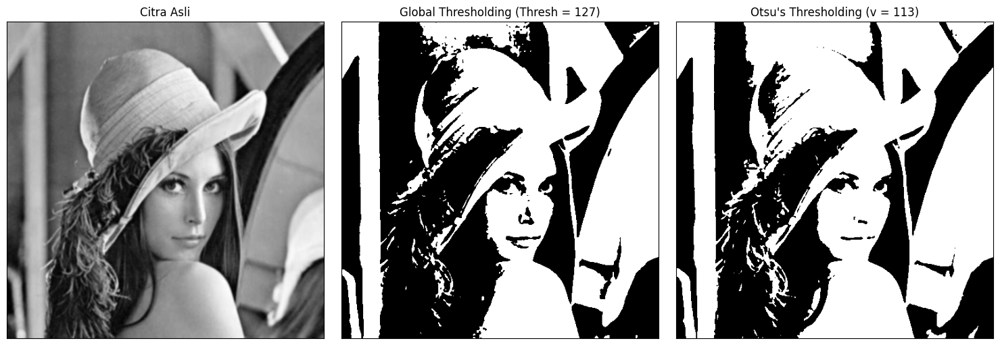

In [ ]:
# 5.Otsu Thresholding manual dan perbandingan pada citra Lena serta KTP

def manual_otsu(gray):
    total_pixels = gray.shape[0] * gray.shape[1]
    hist, _ = np.histogram(gray, bins=256, range=(0, 256))

    prob = hist / total_pixels
    q1 = np.cumsum(prob)
    q2 = 1.0 - q1

    intensity = np.arange(256)
    mu1 = np.cumsum(prob * intensity) / np.maximum(q1, 1e-10)
    mu_total = np.sum(prob * intensity)
    mu2 = (mu_total - np.cumsum(prob * intensity)) / np.maximum(q2, 1e-10)

    variance_b = q1 * q2 * ((mu1 - mu2) ** 2)
    optimal_thresh = np.argmax(variance_b)

    binary_img = np.where(gray > optimal_thresh, 255, 0).astype(np.uint8)
    return binary_img, optimal_thresh

# 5.A Uji coba pada citra Lena
path_lena = '/content/drive/MyDrive/PCVK_2026/Minggu 7/lena.jpg'
img_lena = cv.imread(path_lena, 0)

if img_lena is not None:
    blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)
    global_lena = np.where(blur_lena > 127, 255, 0).astype(np.uint8)
    otsu_lena_img, otsu_lena_val = manual_otsu(blur_lena)

    titles_lena = ['Citra Asli', 'Global Thresholding (Thresh = 127)', f"Otsu's Thresholding (v = {otsu_lena_val})"]
    images_lena = [blur_lena, global_lena, otsu_lena_img]

    plt.figure(figsize=(15, 5))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(images_lena[i], cmap='gray')
        plt.title(titles_lena[i])
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()


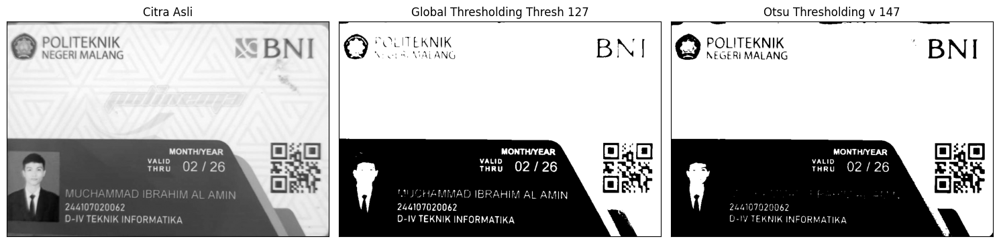

In [ ]:
# 5.B Citra KTP/KTM sendiri
path_ktp_saya = '/content/drive/MyDrive/PCVK_2026/Minggu 7/KTM.jpg'
img_ktp_saya = cv.imread(path_ktp_saya, 0)

if img_ktp_saya is not None:
    global_ktp = np.where(img_ktp_saya > 127, 255, 0).astype(np.uint8)
    otsu_ktp_img, otsu_ktp_val = manual_otsu(img_ktp_saya)

    titles_ktp = ['Citra Asli', 'Global Thresholding Thresh 127', f"Otsu Thresholding v {otsu_ktp_val}"]
    images_ktp = [img_ktp_saya, global_ktp, otsu_ktp_img]

    plt.figure(figsize=(15, 5))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(images_ktp[i], cmap='gray')
        plt.title(titles_ktp[i])
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()

- Penyebab hasil Binary Thresholding bernilai 0 pada citra Lena: Citra lena_gs_lc2.jpg merupakan citra low contrast dengan rentang intensitas sempit hanya berkisar antara 85 hingga 108. Karena seluruh nilai piksel citra berada di bawah ambang batas $127$, semua piksel otomatis dikonversi menjadi $0$.
- Ambang batas agar gambar Lena terlihat: Nilai threshold harus berada di dalam rentang sebaran histogramnya, yaitu di sekitar 88 hingga 93

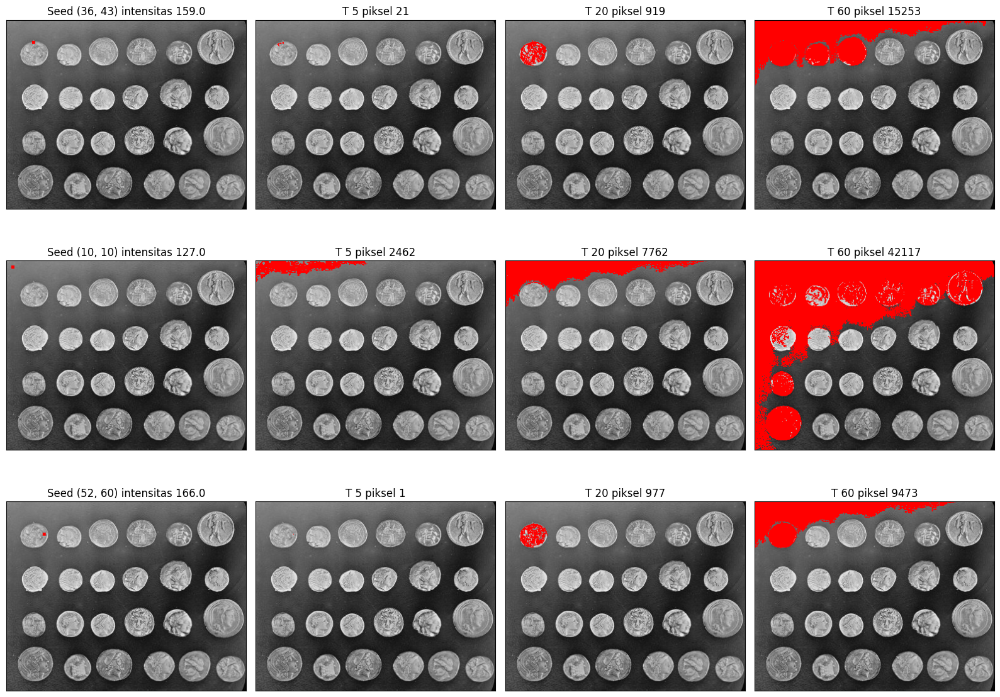

In [ ]:
# 6. Segmentasi berbasis region pada citra data coins menggunakan flood fill 3 seed dan toleransi 5 20 60

gray = data.coins()

seeds = [
    (36, 43),
    (10, 10),
    (52, 60)
]

tolerances = [5, 20, 60]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row_idx, seed in enumerate(seeds):
    seed_r, seed_c = seed
    seed_intensity = gray[seed_r, seed_c]

    rgb_seed = color.gray2rgb(gray)
    rgb_seed[seed_r - 2:seed_r + 3, seed_c - 2:seed_c + 3] = [255, 0, 0]

    axes[row_idx, 0].imshow(rgb_seed)
    axes[row_idx, 0].set_title(f"Seed {seed} intensitas {seed_intensity:.1f}")
    axes[row_idx, 0].set_xticks([])
    axes[row_idx, 0].set_yticks([])

    for col_idx, tol in enumerate(tolerances):
        mask = flood(gray, seed, tolerance=tol, connectivity=1)
        pixel_count = np.sum(mask)

        display_img = color.gray2rgb(gray)
        display_img[mask] = [255, 0, 0]

        axes[row_idx, col_idx + 1].imshow(display_img)
        axes[row_idx, col_idx + 1].set_title(f"T {tol} piksel {pixel_count}")
        axes[row_idx, col_idx + 1].set_xticks([])
        axes[row_idx, col_idx + 1].set_yticks([])

plt.tight_layout()
plt.show()

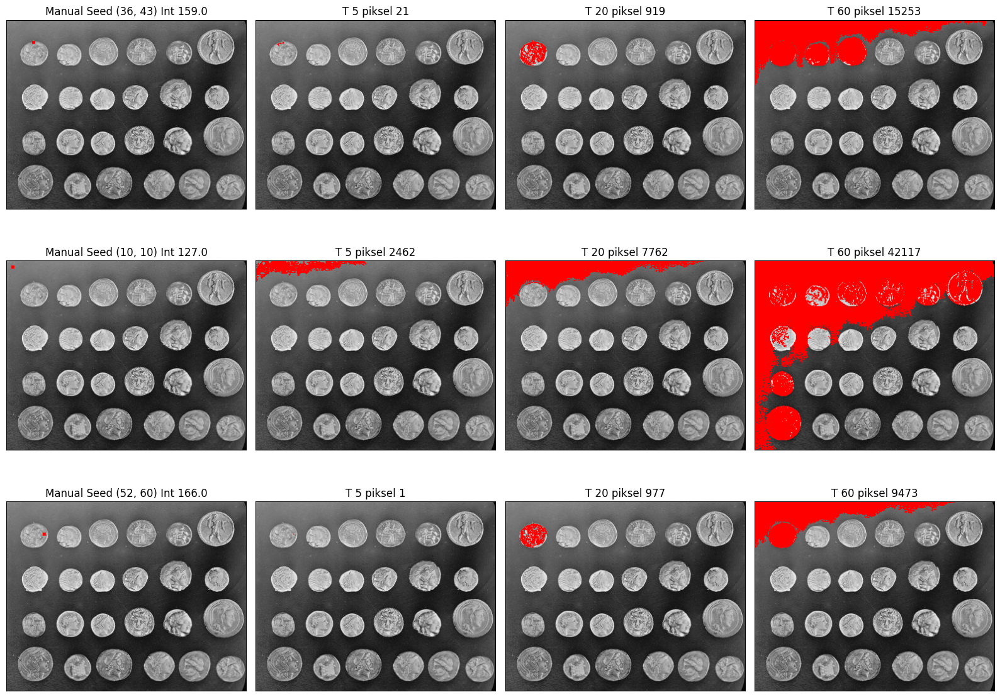

In [ ]:
gray = data.coins()

# 6.A Implementasi manual Region Growing menggunakan antrean BFS
def region_growing_manual(citra, seed_point, ambang):
    h, w = citra.shape
    sr, sc = seed_point
    intensitas_seed = float(citra[sr, sc])

    mask = np.zeros((h, w), dtype=bool)
    dikunjungi = np.zeros((h, w), dtype=bool)

    antrean = deque([(sr, sc)])
    dikunjungi[sr, sc] = True
    mask[sr, sc] = True

    tetangga_4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while antrean:
        r, c = antrean.popleft()
        for dr, dc in tetangga_4:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w:
                if not dikunjungi[nr, nc]:
                    dikunjungi[nr, nc] = True
                    selisih = abs(float(citra[nr, nc]) - intensitas_seed)
                    if selisih <= ambang:
                        mask[nr, nc] = True
                        antrean.append((nr, nc))
    return mask

# Tiga titik seed: koin, latar, tepi koin
daftar_seed = [
    (36, 43),
    (10, 10),
    (52, 60)
]
daftar_ambang = [5, 20, 60]
daftar_seed = [
    (36, 43),
    (10, 10),
    (52, 60)
]
daftar_ambang = [5, 20, 60]

# Visualisasi 6.A Hasil Manual
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for b_idx, s in enumerate(daftar_seed):
    sr, sc = s
    val = gray[sr, sc]

    citra_titik = color.gray2rgb(gray)
    citra_titik[sr - 2:sr + 3, sc - 2:sc + 3] = [255, 0, 0]

    axes[b_idx, 0].imshow(citra_titik)
    axes[b_idx, 0].set_title(f"Manual Seed {s} Int {val:.1f}")
    axes[b_idx, 0].set_xticks([])
    axes[b_idx, 0].set_yticks([])

    for k_idx, ambang in enumerate(daftar_ambang):
        mask_hasil = region_growing_manual(gray, s, ambang)
        jumlah = np.sum(mask_hasil)

        tampilan = color.gray2rgb(gray)
        tampilan[mask_hasil] = [255, 0, 0]

        axes[b_idx, k_idx + 1].imshow(tampilan)
        axes[b_idx, k_idx + 1].set_title(f"T {ambang} piksel {jumlah}")
        axes[b_idx, k_idx + 1].set_xticks([])
        axes[b_idx, k_idx + 1].set_yticks([])

plt.tight_layout()
plt.show()

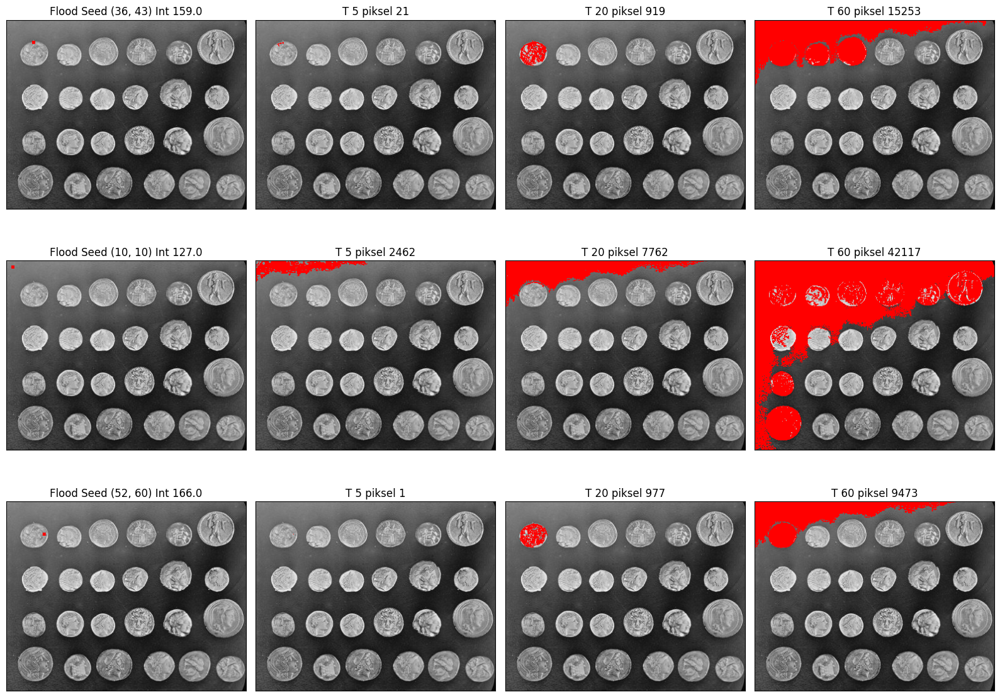

In [ ]:
# 6.B Visualisasi Menggunakan skimage.segmentation.flood
fig2, axes2 = plt.subplots(3, 4, figsize=(16, 12))
for b_idx, s in enumerate(daftar_seed):
    sr, sc = s
    val = gray[sr, sc]

    citra_titik = color.gray2rgb(gray)
    citra_titik[sr - 2:sr + 3, sc - 2:sc + 3] = [255, 0, 0]

    axes2[b_idx, 0].imshow(citra_titik)
    axes2[b_idx, 0].set_title(f"Flood Seed {s} Int {val:.1f}")
    axes2[b_idx, 0].set_xticks([])
    axes2[b_idx, 0].set_yticks([])

    for k_idx, ambang in enumerate(daftar_ambang):
        mask_flood = flood(gray, seed_point=s, tolerance=ambang, connectivity=1)
        jumlah_flood = np.sum(mask_flood)

        tampilan_flood = color.gray2rgb(gray)
        tampilan_flood[mask_flood] = [255, 0, 0]

        axes2[b_idx, k_idx + 1].imshow(tampilan_flood)
        axes2[b_idx, k_idx + 1].set_title(f"T {ambang} piksel {jumlah_flood}")
        axes2[b_idx, k_idx + 1].set_xticks([])
        axes2[b_idx, k_idx + 1].set_yticks([])

plt.tight_layout()
plt.show()

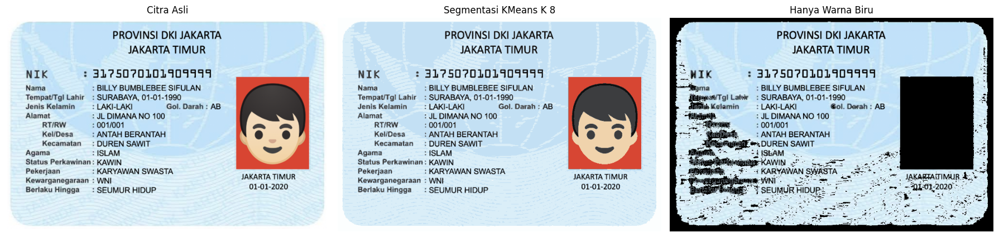

In [ ]:
# 7. Segmentasi warna pada ktp_fulan.jpg menggunakan KMeans dan ruang warna HSV untuk memunculkan latar warna biru

from sklearn.cluster import KMeans

path_ktp = '/content/drive/MyDrive/PCVK_2026/Minggu 7/ktp_fulan.jpg'
img_bgr = cv.imread(path_ktp)

if img_bgr is not None:
    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

    # 7.A Segmentasi K-Means k=8
    piksel = img_rgb.reshape((-1, 3))
    piksel_float = np.float32(piksel)

    kmeans = KMeans(n_clusters=8, random_state=42)
    kmeans.fit(piksel_float)

    pusat_warna = np.uint8(kmeans.cluster_centers_)
    label_klaster = kmeans.labels_

    img_kmeans = pusat_warna[label_klaster.flatten()].reshape(img_rgb.shape)

    # 7.B Filter hanya warna biru menggunakan HSV
    img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)
    H = img_hsv[:, :, 0]
    S = img_hsv[:, :, 1]
    V = img_hsv[:, :, 2]

    mask_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

    hanya_biru = np.zeros_like(img_rgb)
    hanya_biru[mask_biru] = img_rgb[mask_biru]

    # Menampilkan hasil visualisasi
    judul = ['Citra Asli', 'Segmentasi KMeans K 8', 'Hanya Warna Biru']
    daftar_tampilan = [img_rgb, img_kmeans, hanya_biru]

    plt.figure(figsize=(18, 6))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(daftar_tampilan[i])
        plt.title(judul[i])
        plt.axis('off')

    plt.tight_layout()
    plt.show()

**Tugas Kelompok**

In [ ]:
!apt-get update -qq
!apt-get install -y tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
The following NEW packages will be installed:
  tesseract-ocr-ind
0 upgraded, 1 newly installed, 0 to remove and 24 not upgraded.
Need to get 590 kB of archives.
After this operation, 1,138 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 tesseract-ocr-ind all 1:4.1.0-2 [590 kB]
Fetched 590 kB in 1s (622 kB/s)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [ ]:
path_ktp1 = '/content/drive/MyDrive/PCVK_2026/Minggu 7/ktp_ibra.jpg'
path_ktp2 = '/content/drive/MyDrive/PCVK_2026/Minggu 7/ktp_anthea.jpg'
path_ktp3 = '/content/drive/MyDrive/PCVK_2026/Minggu 7/ktp_reza.jpg'

daftar_ktp = [
    ('Ibra', path_ktp1),
    ('Anthea', path_ktp2),
    ('Reza', path_ktp3)
]

citra_list = []
for label, path in daftar_ktp:
    bgr = cv.imread(path)
    if bgr is not None:
        gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
        rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
        citra_list.append((label, bgr, gray, rgb))

In [ ]:
hasil_segmentasi = []

for label, bgr, gray, rgb in citra_list:
    ret, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

    otsu_rgb = cv.cvtColor(otsu, cv.COLOR_GRAY2RGB)
    adaptive_rgb = cv.cvtColor(adaptive, cv.COLOR_GRAY2RGB)

    hasil_segmentasi.append({
        'label': label,
        'asli_rgb': rgb,
        'otsu': otsu,
        'otsu_rgb': otsu_rgb,
        'adaptive': adaptive,
        'adaptive_rgb': adaptive_rgb
    })

In [ ]:
config_ocr = '--psm 6 -l ind'
hasil_teks_ocr = []

for item in hasil_segmentasi:
    teks_w = pytesseract.image_to_string(item['asli_rgb'], config=config_ocr)
    teks_o = pytesseract.image_to_string(item['otsu'], config=config_ocr)
    teks_a = pytesseract.image_to_string(item['adaptive'], config=config_ocr)

    hasil_teks_ocr.append({
        'label': item['label'],
        'teks_warna': teks_w,
        'teks_otsu': teks_o,
        'teks_adaptive': teks_a
    })

    print(f"=== HASIL PEMBACAAN {item['label']} ===")
    print("--- Berwarna ---")
    print(teks_w.strip())
    print("--- Otsu ---")
    print(teks_o.strip())
    print("--- Adaptive ---")
    print(teks_a.strip())
    print("=" * 40)

=== HASIL PEMBACAAN Ibra ===
--- Berwarna ---
———— PROVINSIJAWA TIMUR”
6 KRBUPATENPASURUAN oo”

NIK: Ingatan OPT i —

Nama - MUGHAMMAD IBRAHIMAL AMIN ——

Tempat/Tgi Lahir 4 MAN JM his 8 DAS. — ——— ——

Alamat 2 Ga "ee. LN TE
RTRW 05m —— — .g
Kel/Desa —: LA — ——
Kecamatan : - 5 b-

Agama : ISLAM 2

Status Perkawinan BELUM KAWIN

Pekerjaan : PELAJAR/MAHASISWA PASURUAN

Kewarganegaraan: WNI 2» ——

| Berlaku Hingga: SEUMUR HIDUP .
--- Otsu ---
PROVINSI JAWA TIMUR...
KABUPATEN PASURYAMF--
NIK 2 Jen rn as PI
Nama : MCHAMMAD IBRAHIM AL AMIN
TempatTgi Lahir : “a "IN SI bu D0 CNG
Jeniskelamin —: LAKI-LAKI Goi. Dagah :-
Alamat 2 SA el La A2 €
RTRW :-m -.
| Kel/Dasa : Wi ah PO yaa —
: Kecamatan : Wa -
— Agama : #SLAM -
Status Perkawinart BELUM KAWIN
— Pekerjaan : PELAJAR/MAHASISWA PASURUAN
— Kewarganegaraan: WNI
Berlaku Hingga: SEUMUR HIDUP 7. ma
--- Adaptive ---
FP ———— PHOVINSAWA HMD
PA KABUPATENPASURGAN
NIK oo aa Sh Pe — TA
On aa
Damat orng
Ae ae
Status Perkawinart BELUM KAWIN Oa Ke am Ma
2 Ber

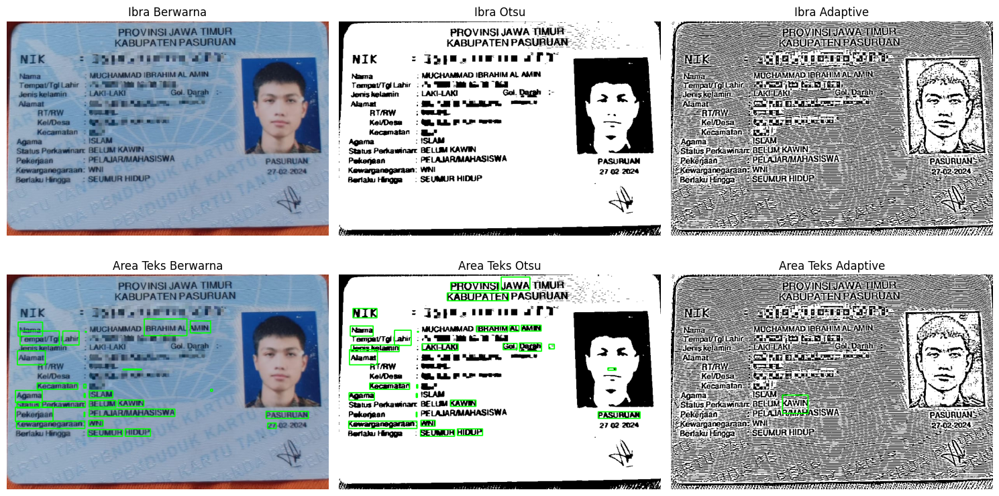

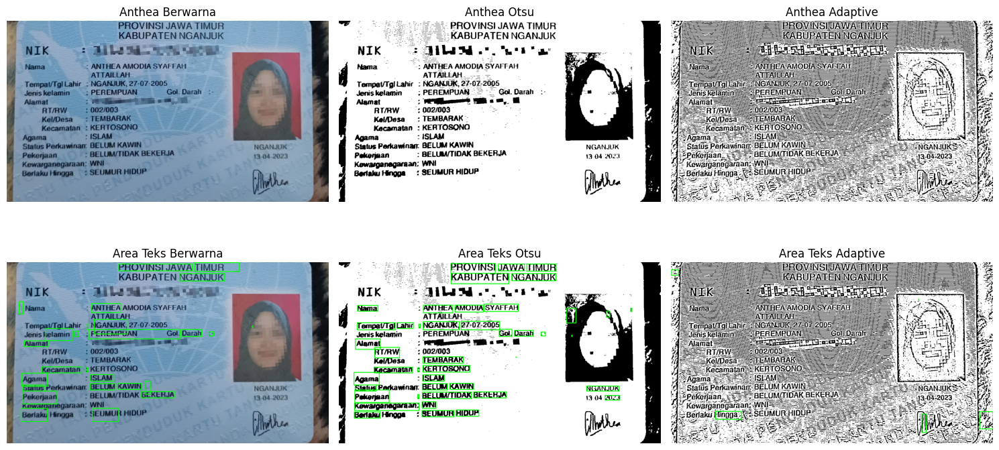

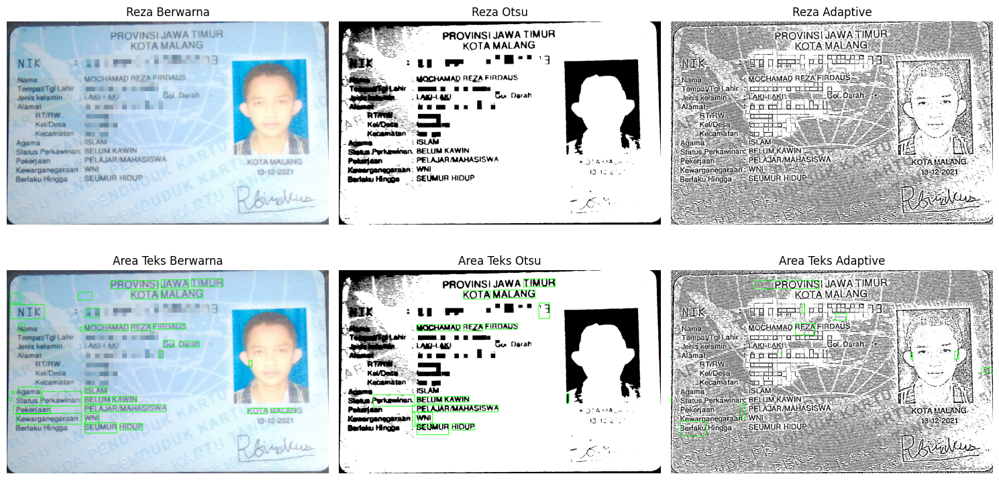

In [ ]:
from pytesseract import Output

for item in hasil_segmentasi:
    data_w = pytesseract.image_to_data(item['asli_rgb'], config=config_ocr, output_type=Output.DICT)
    kotak_w = item['asli_rgb'].copy()
    for i in range(len(data_w['text'])):
        conf = int(data_w['conf'][i])
        if conf > 60 and data_w['text'][i].strip() != "":
            x, y, w, h = data_w['left'][i], data_w['top'][i], data_w['width'][i], data_w['height'][i]
            cv.rectangle(kotak_w, (x, y), (x + w, y + h), (0, 255, 0), 2)

    data_o = pytesseract.image_to_data(item['otsu'], config=config_ocr, output_type=Output.DICT)
    kotak_o = item['otsu_rgb'].copy()
    for i in range(len(data_o['text'])):
        conf = int(data_o['conf'][i])
        if conf > 60 and data_o['text'][i].strip() != "":
            x, y, w, h = data_o['left'][i], data_o['top'][i], data_o['width'][i], data_o['height'][i]
            cv.rectangle(kotak_o, (x, y), (x + w, y + h), (0, 255, 0), 2)

    data_a = pytesseract.image_to_data(item['adaptive'], config=config_ocr, output_type=Output.DICT)
    kotak_a = item['adaptive_rgb'].copy()
    for i in range(len(data_a['text'])):
        conf = int(data_a['conf'][i])
        if conf > 60 and data_a['text'][i].strip() != "":
            x, y, w, h = data_a['left'][i], data_a['top'][i], data_a['width'][i], data_a['height'][i]
            cv.rectangle(kotak_a, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.figure(figsize=(15, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(item['asli_rgb'])
    plt.title(f"{item['label']} Berwarna")
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(item['otsu'], cmap='gray')
    plt.title(f"{item['label']} Otsu")
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.imshow(item['adaptive'], cmap='gray')
    plt.title(f"{item['label']} Adaptive")
    plt.axis('off')

    plt.subplot(2, 3, 4)
    plt.imshow(kotak_w)
    plt.title("Area Teks Berwarna")
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(kotak_o)
    plt.title("Area Teks Otsu")
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.imshow(kotak_a)
    plt.title("Area Teks Adaptive")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
# 5 Menghitung kecocokan 10 kata acuan rata rata confidence dan menampilkan tabel ringkasan

kata_acuan = [
    "PROVINSI", "MALANG", "NIK", "Nama", "Tempat/Tgl",
    "LAKI-LAKI", "Alamat", "ISLAM", "KAWIN", "WNI"
]

def evaluasi_kata(teks, data_dict, kata_list):
    cocok = 0
    baris = []
    for kata in kata_list:
        if kata.lower() in teks.lower():
            cocok += 1
            baris.append(kata)
        else:
            baris.append("Tidak Cocok")
    persen = (cocok / len(kata_list)) * 100

    conf_valid = [int(c) for c, t in zip(data_dict['conf'], data_dict['text']) if int(c) > 0 and t.strip() != ""]
    rata_conf = np.mean(conf_valid) if len(conf_valid) > 0 else 0
    return baris, cocok, persen, rata_conf

for idx, item in enumerate(hasil_segmentasi):
    teks_w = hasil_teks_ocr[idx]['teks_warna']
    teks_o = hasil_teks_ocr[idx]['teks_otsu']
    teks_a = hasil_teks_ocr[idx]['teks_adaptive']

    data_w = pytesseract.image_to_data(item['asli_rgb'], config=config_ocr, output_type=Output.DICT)
    data_o = pytesseract.image_to_data(item['otsu'], config=config_ocr, output_type=Output.DICT)
    data_a = pytesseract.image_to_data(item['adaptive'], config=config_ocr, output_type=Output.DICT)

    list_w, jml_w, prs_w, cnf_w = evaluasi_kata(teks_w, data_w, kata_acuan)
    list_o, jml_o, prs_o, cnf_o = evaluasi_kata(teks_o, data_o, kata_acuan)
    list_a, jml_a, prs_a, cnf_a = evaluasi_kata(teks_a, data_a, kata_acuan)

    df_10_kata = pd.DataFrame({
        'No.': range(1, 11),
        'Teks Sebenarnya': kata_acuan,
        'OCR Citra Berwarna': list_w,
        'OCR Otsu': list_o,
        'OCR Adaptive': list_a
    })
    print(f"\nTabel 10 Kata Acuan ({item['label']}):")
    display(df_10_kata)

    df_rekap_metode = pd.DataFrame({
        'Citra Masukan OCR': ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive'],
        'Item Terbaca Tepat': [jml_w, jml_o, jml_a],
        'Kecocokan (%)': [f"{prs_w:.1f}%", f"{prs_o:.1f}%", f"{prs_a:.1f}%"],
        'Rata-rata Confidence': [f"{cnf_w:.2f}", f"{cnf_o:.2f}", f"{cnf_a:.2f}"]
    })
    print(f"\nTabel Ringkasan ({item['label']}):")
    display(df_rekap_metode)


Tabel 10 Kata Acuan (Ibra):


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,Tidak Cocok
1,2,MALANG,Tidak Cocok,Tidak Cocok,Tidak Cocok
2,3,NIK,NIK,NIK,NIK
3,4,Nama,Nama,Nama,Tidak Cocok
4,5,Tempat/Tgl,Tidak Cocok,Tidak Cocok,Tidak Cocok
5,6,LAKI-LAKI,Tidak Cocok,LAKI-LAKI,Tidak Cocok
6,7,Alamat,Alamat,Alamat,Tidak Cocok
7,8,ISLAM,ISLAM,Tidak Cocok,Tidak Cocok
8,9,KAWIN,KAWIN,KAWIN,KAWIN
9,10,WNI,WNI,WNI,Tidak Cocok



Tabel Ringkasan (Ibra):


,Citra Masukan OCR,Item Terbaca Tepat,Kecocokan (%),Rata-rata Confidence
0,Berwarna asli,7,70.0%,57.98
1,Segmentasi Otsu,7,70.0%,55.91
2,Segmentasi Adaptive,2,20.0%,20.80



Tabel 10 Kata Acuan (Anthea):


...

,Citra Masukan OCR,Item Terbaca Tepat,Kecocokan (%),Rata-rata Confidence
0,Berwarna asli,6,60.0%,47.01
1,Segmentasi Otsu,7,70.0%,59.30
2,Segmentasi Adaptive,1,10.0%,23.96



Tabel 10 Kata Acuan (Reza):


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,Tidak Cocok
1,2,MALANG,MALANG,MALANG,MALANG
2,3,NIK,NIK,Tidak Cocok,Tidak Cocok
3,4,Nama,Tidak Cocok,Tidak Cocok,Nama
4,5,Tempat/Tgl,Tidak Cocok,Tidak Cocok,Tidak Cocok
5,6,LAKI-LAKI,Tidak Cocok,Tidak Cocok,Tidak Cocok
6,7,Alamat,Tidak Cocok,Tidak Cocok,Tidak Cocok
7,8,ISLAM,ISLAM,ISLAM,Tidak Cocok
8,9,KAWIN,KAWIN,KAWIN,KAWIN
9,10,WNI,WNI,WNI,WNI



Tabel Ringkasan (Reza):


,Citra Masukan OCR,Item Terbaca Tepat,Kecocokan (%),Rata-rata Confidence
0,Berwarna asli,6,60.0%,55.88
1,Segmentasi Otsu,5,50.0%,46.75
2,Segmentasi Adaptive,4,40.0%,24.14


**Pertanyaan analisis:**

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari
tabel.
- Citra hasil Segmentasi Otsu menghasilkan pembacaan paling tepat. Buktinya terlihat pada tabel ringkasan di mana Segmentasi Otsu memperoleh persentase kecocokan paling tinggi dibanding citra berwarna asli maupun Segmentasi Adaptive
2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks
tidak terbaca.
- Angka 1 atau 7 sering terbaca menjadi tanda tanya, garis tegak, atau angka lain, serta angka 0 kerap tertukar dengan huruf kapital O.
- Kalimat seperti Tempat garis miring Tgl Lahir tanda baca garis miringnya sering hilang atau tidak terbaca sehingga kata terpotong
3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil
percobaan.
- Segmentasi tidak selalu meningkatkan ketepatan OCR.
Meskipun metode biner seperti Otsu terbukti efektif menghilangkan latar belakang, metode Adaptive Thresholding pada praktikum ini justru rentan memunculkan noise berupa bintik-bintik hitam di sekitar huruf dan latar polos
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
- Warna dan pola watermark atau garis halus pada latar KTP memiliki tingkat kontras yang dekat dengan warna tulisan
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
- Metode dengan rata-rata confidence tertinggi tidak selalu memiliki kecocokan tertinggi.
Skor confidence hanya mengukur tingkat kepastian internal mesin OCR terhadap pola bentuk piksel yang dicocokkan ke database model